# Detecting fraudulent card payments: from rules to a cost-based model

**Business question.** Kestrel Pay (a fictitious payment provider) reviews suspicious card payments with a small
fraud team. Today, alerts come from three rules. Too many alerts are false, and too much fraud gets through.
**Which payments should the team review, so that fraud losses plus review costs are as low as possible?**

**Approach.**
1. Explore six months of payments (January to June 2025) and the fraud patterns in them.
2. Build behavioural features from each customer's *past* payments only.
3. Train on January-March, tune the alert threshold on April, report on May-June, as a real deployment would.
4. Compare the current rules, a logistic regression and gradient boosting **in euros**, not only in model scores.

*The data is synthetic: real payment data is confidential. The simulation includes legitimate behaviour that looks
suspicious (trips abroad, foreign websites, new phones, night workers) so the problem is not artificially easy.*

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import fraud_pipeline as fp
%matplotlib inline

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "figure.dpi": 110})
data = pd.read_csv(fp.DATA_FILE, parse_dates=["timestamp"])
print(f"{len(data):,} payments, {data.customer_id.nunique():,} customers, "
      f"{data.is_fraud.sum()} fraudulent ({data.is_fraud.mean():.2%})")
data.head()

241,831 payments, 3,000 customers, 972 fraudulent (0.40%)


,transaction_id,timestamp,customer_id,amount,merchant_category,channel,device_id,country,home_country,tenure_days,is_fraud,fraud_type
0,T0000000,2025-01-01 00:05:31,CU02158,31.850,health,card_present,CU02158-D2,FR,FR,2380,0,NaN
1,T0000001,2025-01-01 00:06:18,CU01121,14.530,health,card_present,CU01121-D0,FR,FR,1061,0,NaN
2,T0000002,2025-01-01 00:09:00,CU01494,20.180,restaurants,card_present,CU01494-D0,FR,FR,1610,0,NaN
3,T0000003,2025-01-01 00:11:58,CU00910,35.530,grocery,card_present,CU00910-D0,FR,FR,1628,0,NaN
4,T0000004,2025-01-01 00:17:42,CU01287,209.480,online_retail,online,CU01287-D1,FR,FR,520,0,NaN


## 1. Exploring the payments

Fraud is rare: about 4 payments in 1,000. A model that says "never fraud" would be 99.6% accurate and useless,
so accuracy is the wrong yardstick. What matters is how much fraud is caught and how many alerts it takes.

In [2]:
fraud = data[data.is_fraud == 1]
summary = fraud.groupby("fraud_type").agg(payments=("amount", "size"), amount_eur=("amount", "sum"),
                                          median_amount=("amount", "median"))
summary.loc["all fraud"] = [len(fraud), fraud.amount.sum(), fraud.amount.median()]
summary

,payments,amount_eur,median_amount
fraud_type,,,
account_takeover,379.000,"111,424.180",229.130
card_testing,498.000,"54,531.090",3.735
quiet,95.000,"9,111.270",79.900
all fraud,972.000,"175,066.540",110.075


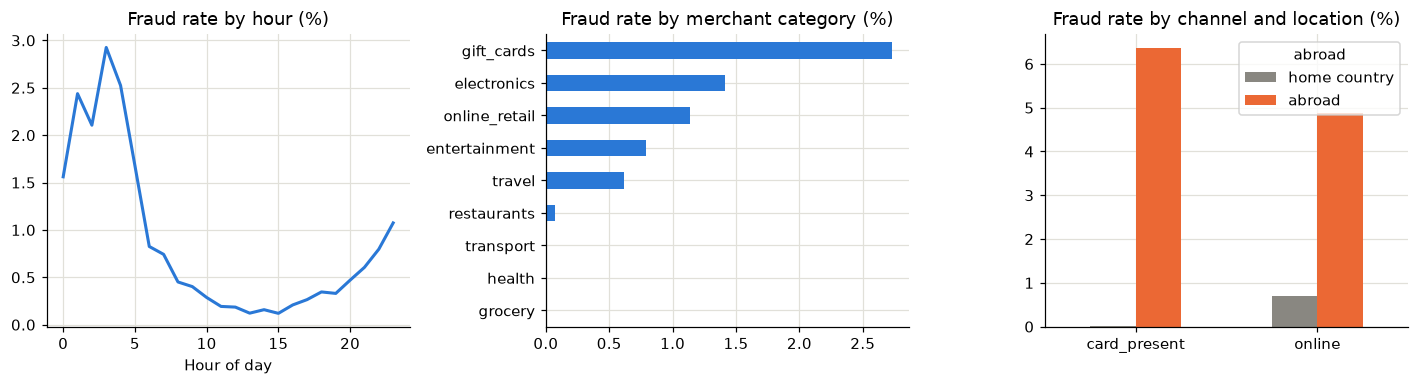

In [3]:
data["hour"] = data.timestamp.dt.hour
data["abroad"] = data.country != data.home_country
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
data.groupby("hour").is_fraud.mean().mul(100).plot(ax=axes[0], color=fp.BLUE, lw=2)
axes[0].set(title="Fraud rate by hour (%)", xlabel="Hour of day", ylabel="")
(data.groupby("merchant_category").is_fraud.mean().mul(100).sort_values()
     .plot.barh(ax=axes[1], color=fp.BLUE))
axes[1].set(title="Fraud rate by merchant category (%)", ylabel="")
(data.groupby(["channel", "abroad"]).is_fraud.mean().mul(100).unstack()
     .rename(columns={False: "home country", True: "abroad"})
     .plot.bar(ax=axes[2], color=[fp.GREY, fp.ORANGE], rot=0))
axes[2].set(title="Fraud rate by channel and location (%)", xlabel="")
plt.tight_layout()
plt.show()

Fraud concentrates at night, on electronics and gift cards, and online abroad. But each signal alone is weak:
most night-time payments, most foreign payments and most electronics purchases are legitimate. That is exactly
why the current rules raise so many false alerts.

## 2. Behavioural features, without looking into the future

Fraud is visible in *behaviour*: a burst of payments, a new device, an amount far above the customer's habits,
tiny "test" payments just before a large one. Each feature is computed from the customer's **previous** payments
only (`closed="left"` time windows, shifted rolling means): a feature that peeks at later payments would make the
model look better on paper than it can ever be in production.

In [4]:
df = fp.build_features(data)
features = fp.NUMERIC_FEATURES + fp.CATEGORICAL_FEATURES
df[["customer_id", "timestamp", "amount", "amount_vs_usual", "new_device", "count_1h",
    "small_payments_10min", "is_fraud"]].tail(8)

,customer_id,timestamp,amount,amount_vs_usual,new_device,count_1h,small_payments_10min,is_fraud
241823,CU00444,2025-06-30 23:23:27,24.080,0.662,0,4.000,0.000,0
241824,CU01827,2025-06-30 23:26:01,102.690,2.584,0,0.000,0.000,0
241825,CU01831,2025-06-30 23:27:55,22.260,0.169,1,0.000,0.000,0
241826,CU00406,2025-06-30 23:39:27,311.110,3.174,0,0.000,0.000,0
241827,CU01209,2025-06-30 23:40:01,24.370,0.248,0,0.000,0.000,0
241828,CU02841,2025-06-30 23:43:38,79.990,1.455,0,0.000,0.000,0
241829,CU00552,2025-06-30 23:44:25,36.160,0.829,0,0.000,0.000,0
241830,CU02546,2025-06-30 23:48:53,36.380,0.305,0,0.000,0.000,0


In [5]:
comparison = df.groupby("is_fraud")[["amount_vs_usual", "new_device", "new_country", "count_1h",
                                      "small_payments_10min", "is_night"]].mean()
comparison.index = ["legitimate", "fraud"]
comparison.T

,legitimate,fraud
amount_vs_usual,1.135,4.297
new_device,0.018,0.191
new_country,0.021,0.091
count_1h,0.185,1.167
small_payments_10min,0.004,0.303
is_night,0.058,0.316


## 3. A split that mirrors real life

The model is trained on January-March, the alert threshold is chosen on April, and every figure reported below
comes from May-June: payments the model has never seen, later in time.

In [6]:
train = df[df.timestamp < fp.TRAIN_END]
validation = df[(df.timestamp >= fp.TRAIN_END) & (df.timestamp < fp.VALIDATION_END)]
test = df[df.timestamp >= fp.VALIDATION_END]
test_days = (test.timestamp.max().normalize() - test.timestamp.min().normalize()).days + 1
pd.DataFrame({"payments": [len(train), len(validation), len(test)],
              "fraudulent": [train.is_fraud.sum(), validation.is_fraud.sum(), test.is_fraud.sum()]},
             index=["train (Jan-Mar)", "validation (Apr)", "test (May-Jun)"])

,payments,fraudulent
train (Jan-Mar),120293,467
validation (Apr),40346,189
test (May-Jun),81192,316


## 4. Rules versus models, in euros

**Cost model.** Reviewing an alert costs about **€8** (12 minutes of an analyst at €40/hour). A fraud that is
not alerted costs its full amount. A fraud that is alerted is assumed to be stopped. The best threshold for each
model is the one with the lowest *review cost + fraud missed* on April.

In [7]:
rows = [{"approach": "Current rules", **fp.outcome(fp.rules_flag(test), test, test_days)}]
models, scores = fp.make_models(), {}
for name, model in models.items():
    model.fit(train[features], train.is_fraud)
    threshold, _ = fp.best_threshold(model.predict_proba(validation[features])[:, 1], validation)
    scores[name] = model.predict_proba(test[features])[:, 1]
    rows.append({"approach": f"{name} (threshold {threshold:.2f})",
                 **fp.outcome(scores[name] >= threshold, test, test_days)})
results = pd.DataFrame(rows).set_index("approach")
results[["alerts_per_day", "recall_count", "recall_amount", "precision", "review_cost",
         "fraud_amount_missed", "total_cost"]]

,alerts_per_day,recall_count,recall_amount,precision,review_cost,fraud_amount_missed,total_cost
approach,,,,,,,
Current rules,42.800,0.386,0.442,0.047,"20,904.000","31,731.900","52,635.900"
Logistic regression (threshold 0.89),14.800,0.661,0.781,0.232,"7,224.000","12,449.010","19,673.010"
Gradient boosting (threshold 0.58),13.200,0.826,0.870,0.325,"6,432.000","7,378.350","13,810.350"


Gradient boosting catches far more fraud **with fewer alerts**: the team reviews about 13 payments a day instead
of 43, and one alert in three is a real fraud instead of one in twenty. Over May-June the total cost falls by
roughly three quarters.

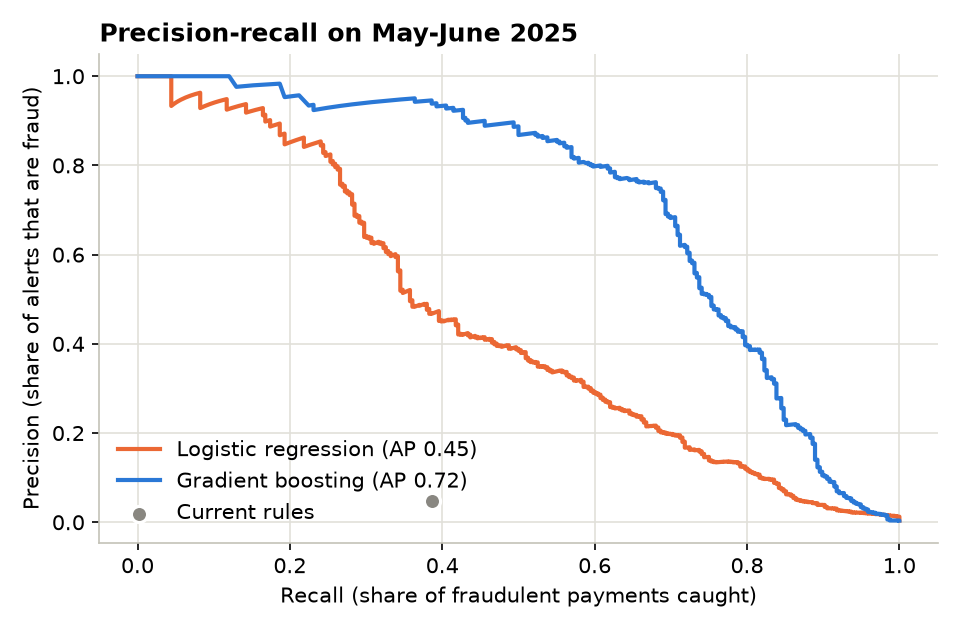

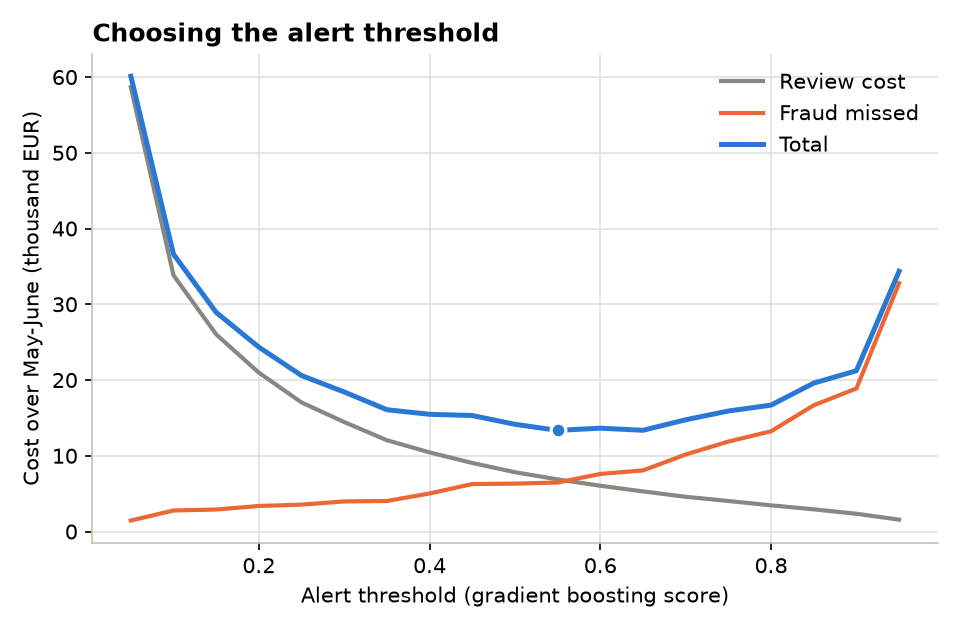

In [8]:
from IPython.display import Image, display
display(Image(filename=str(fp.IMAGES_DIR / "precision_recall.png"), width=620))
display(Image(filename=str(fp.IMAGES_DIR / "cost_by_threshold.png"), width=620))

The cost curve is flat around its minimum: any threshold between about 0.45 and 0.65 gives a similar total
cost. That matters for the decision: the threshold can be set to match the team's capacity without losing much.

## 5. What drives the model, and what it misses

Permutation importance measures how much the model's average precision drops when one signal is shuffled.
The leading signals are the ones a fraud analyst would recognise, which makes the alerts explainable.

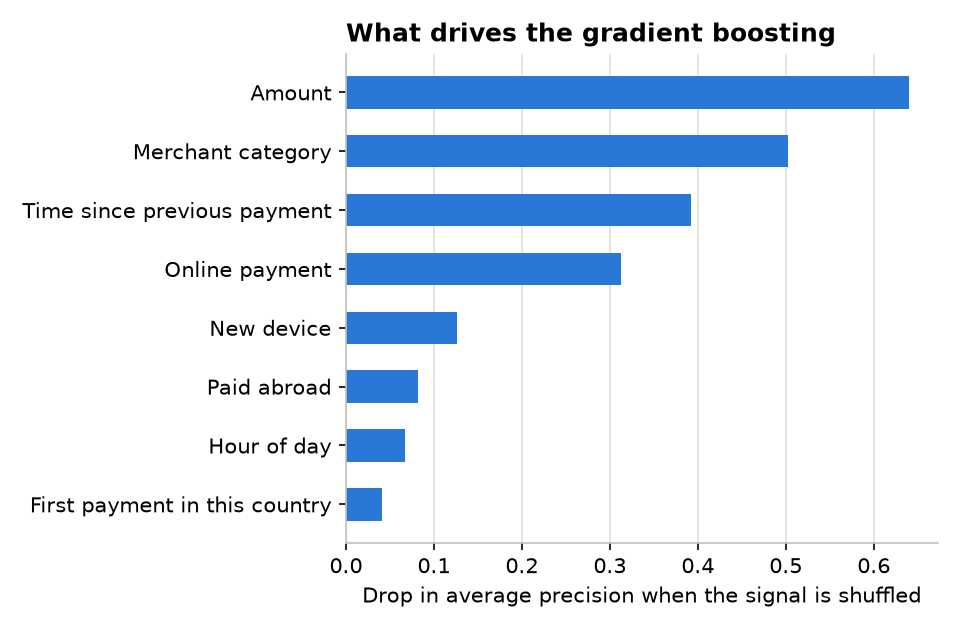

,caught by gradient boosting,caught by rules
fraud_type,,
account_takeover,0.790,0.387
card_testing,0.988,0.472
quiet,0.222,0.000


In [9]:
display(Image(filename=str(fp.IMAGES_DIR / "drivers.png"), width=620))
best = max(scores, key=lambda n: results.loc[results.index.str.startswith(n), "recall_amount"].iloc[0])
flags = scores[best] >= fp.best_threshold(models[best].predict_proba(validation[features])[:, 1], validation)[0]
by_pattern = (test.assign(alerted=flags, rules=fp.rules_flag(test))[test.is_fraud == 1]
                  .groupby("fraud_type")[["alerted", "rules"]].mean()
                  .rename(columns={"alerted": f"caught by {best.lower()}", "rules": "caught by rules"}))
by_pattern

Account takeovers and card testing are caught well. "Quiet" fraud, single payments that look like the
customer's usual spending, mostly gets through: no behavioural model will see it, and it is a small share of the
amount. It needs other controls (strong customer authentication, customer reports).

## 6. Recommendation

| | Current rules | Gradient boosting |
|---|---|---|
| Alerts per day | ~43 | ~13 |
| Share of alerts that are fraud | ~5% | ~33% |
| Fraud caught (amount) | ~44% | ~87% |
| Total cost, May-June | ~€53k | ~€14k |

1. **Replace the rules with the model** for alerting, starting with a two-week shadow run where both run side by side.
2. **Set the threshold from capacity**: at about 13 alerts a day, the team handles the volume with spare time for
   investigations; lowering the threshold catches a little more fraud for many more alerts.
3. **Keep a rule for very large payments** as a safety net, and retrain monthly as fraud patterns change.
4. **Measure** weekly: fraud caught in euros, alerts per day, share of alerts confirmed as fraud.

*Limits: synthetic data; the cost model ignores customer friction from false alerts and assumes alerted fraud is
always stopped. A real project would calibrate both with the fraud team.*